# 01 — Exploration de la couche Bronze | Panier Vert

**Objectif :** inventorier et diagnostiquer les fichiers bruts issus des collectes Instacart, Open Food Facts, RappelConso et Scraping.

Ce notebook est en lecture seule : il ne modifie et ne supprime aucun fichier source.

**Résultats attendus :**
- inventaire des fichiers Parquet ;
- nombre de lignes et colonnes ;
- aperçu des données et types ;
- valeurs manquantes ;
- statistiques descriptives simples ;
- premières alertes de qualité à investiguer dans la couche Silver.

## 1. Initialisation de l'environnement

Le notebook doit être exécuté depuis la racine du projet `projet_mspr_panier_vert`, avec le kernel **Python (Panier Vert)**.

In [1]:
from pathlib import Path
import sys
import json
import warnings

import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

# Recherche de la racine du projet à partir du répertoire courant
cwd = Path.cwd()
candidates = [cwd, *cwd.parents]
ROOT = next(
    (p for p in candidates if (p / "data" / "raw").is_dir() and (p / "src").is_dir()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Racine du projet introuvable. Ouvre Jupyter depuis "
        "projet_mspr_panier_vert ou adapte ROOT manuellement."
    )

RAW_DIR = ROOT / "data" / "raw"

print("Racine du projet :", ROOT)
print("Dossier Bronze   :", RAW_DIR)
print("Python           :", sys.executable)
print("Pandas           :", pd.__version__)

Racine du projet : c:\Users\akono\projet_mspr_panier_vert
Dossier Bronze   : c:\Users\akono\projet_mspr_panier_vert\data\raw
Python           : c:\Users\akono\projet_mspr_panier_vert\.venv\Scripts\python.exe
Pandas           : 3.1.1


## 2. Inventaire des fichiers Bronze

On examine uniquement `data/raw` et on exclut volontairement `_smoke`, qui contient les sorties des tests rapides, afin de ne pas mélanger les tests avec la collecte principale.

In [2]:
parquet_files = sorted(
    p for p in RAW_DIR.rglob("*.parquet")
    if "_smoke" not in p.parts
)

inventory = pd.DataFrame([
    {
        "source": p.parent.name,
        "fichier": p.name,
        "chemin_relatif": str(p.relative_to(ROOT)),
        "taille_Mo": round(p.stat().st_size / (1024 ** 2), 2),
    }
    for p in parquet_files
])

display(inventory)

if inventory.empty:
    print("Aucun fichier Parquet trouvé dans data/raw.")

,source,fichier,chemin_relatif,taille_Mo
0,instacart,aisles.parquet,data\raw\instacart\aisles.parquet,0.00
1,instacart,departments.parquet,data\raw\instacart\departments.parquet,0.00
2,instacart,order_products__prior.parquet,data\raw\instacart\order_products__prior.parquet,125.81
3,instacart,order_products__train.parquet,data\raw\instacart\order_products__train.parquet,5.37
4,instacart,orders.parquet,data\raw\instacart\orders.parquet,31.60
5,instacart,products.parquet,data\raw\instacart\products.parquet,1.45
6,openfoodfacts,products_20261117.parquet,data\raw\openfoodfacts\products_20261117.parquet,0.21
7,rappelconso,rappelconso.parquet,data\raw\rappelconso\rappelconso.parquet,4.36
8,scraping,articles_20261117.parquet,data\raw\scraping\articles_20261117.parquet,0.05


## 3. Métadonnées et schéma des fichiers

Cette étape utilise les métadonnées Parquet : elle permet de connaître le nombre de lignes, les colonnes et les types sans charger entièrement les gros fichiers en mémoire.

In [3]:
metadata_rows = []

for path in parquet_files:
    parquet_file = pq.ParquetFile(path)
    metadata_rows.append({
        "source": path.parent.name,
        "fichier": path.name,
        "lignes": parquet_file.metadata.num_rows,
        "colonnes": parquet_file.metadata.num_columns,
        "groupes": parquet_file.metadata.num_row_groups,
    })

metadata_df = pd.DataFrame(metadata_rows)
display(metadata_df)

,source,fichier,lignes,colonnes,groupes
0,instacart,aisles.parquet,134,2,1
1,instacart,departments.parquet,21,2,1
2,instacart,order_products__prior.parquet,32434489,4,551
3,instacart,order_products__train.parquet,1384617,4,24
4,instacart,orders.parquet,3421083,7,104
5,instacart,products.parquet,49688,4,3
6,openfoodfacts,products_20261117.parquet,1000,15,1
7,rappelconso,rappelconso.parquet,19018,37,1
8,scraping,articles_20261117.parquet,7,13,1


In [4]:
# Détail du schéma de chaque fichier
for path in parquet_files:
    print("\n" + "=" * 90)
    print(f"SOURCE : {path.parent.name} | FICHIER : {path.name}")
    print("=" * 90)
    parquet_file = pq.ParquetFile(path)
    print(parquet_file.schema)


SOURCE : instacart | FICHIER : aisles.parquet
required group field_id=-1 schema {
  optional int32 field_id=-1 aisle_id;
  optional binary field_id=-1 aisle (String);
}


SOURCE : instacart | FICHIER : departments.parquet
required group field_id=-1 schema {
  optional int32 field_id=-1 department_id;
  optional binary field_id=-1 department (String);
}


SOURCE : instacart | FICHIER : order_products__prior.parquet
required group field_id=-1 schema {
  optional int64 field_id=-1 order_id;
  optional int64 field_id=-1 product_id;
  optional int32 field_id=-1 add_to_cart_order;
  optional int32 field_id=-1 reordered (Int(bitWidth=8, isSigned=true));
}


SOURCE : instacart | FICHIER : order_products__train.parquet
required group field_id=-1 schema {
  optional int64 field_id=-1 order_id;
  optional int64 field_id=-1 product_id;
  optional int32 field_id=-1 add_to_cart_order;
  optional int32 field_id=-1 reordered (Int(bitWidth=8, isSigned=true));
}


SOURCE : instacart | FICHIER : orders.

## 4. Aperçu des données

On lit uniquement un petit échantillon de chaque fichier. Cela évite de charger intégralement les grandes tables Instacart, notamment `order_products__prior.parquet`.

In [5]:
samples = {}

for path in parquet_files:
    parquet_file = pq.ParquetFile(path)
    batches = parquet_file.iter_batches(batch_size=8)
    try:
        batch = next(batches)
        sample_df = batch.to_pandas()
        samples[str(path.relative_to(ROOT))] = sample_df
        print("\n" + "=" * 90)
        print(f"{path.parent.name}/{path.name}")
        display(sample_df.head(5))
    except StopIteration:
        print(f"Fichier vide : {path}")


instacart/aisles.parquet


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation



instacart/departments.parquet


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol



instacart/order_products__prior.parquet


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


... (8 outputs left out)


rappelconso/rappelconso.parquet


,gtin,numero_fiche,numero_version,nature_juridique_rappel,categorie_produit,sous_categorie_produit,marque_produit,modeles_ou_references,identification_produits,conditionnements,date_debut_commercialisation,date_date_fin_commercialisation,temperature_conservation,marque_salubrite,informations_complementaires,zone_geographique_de_vente,distributeurs,motif_rappel,risques_encourus,preconisations_sanitaires,description_complementaire_risque,conduites_a_tenir_par_le_consommateur,numero_contact,modalites_de_compensation,date_de_fin_de_la_procedure_de_rappel,informations_complementaires_publiques,liens_vers_les_images,lien_vers_la_liste_des_produits,lien_vers_la_liste_des_distributeurs,lien_vers_affichette_pdf,lien_vers_la_fiche_rappel,rappel_guid,date_publication,libelle,id,_source,_ingested_at
0,7079317191322,2026-10-0056,2,volontaire (sans arrêté préfectoral),"appareils électriques, outils","appareils électriques, électroménager",jatrhg,s1_72_8m,7079317191322$lots sans numéro ou fabriqué jusqu'au 31 août 2026.$non concerné$$,NaN,NaN,2026-10-31,NaN,NaN,NaN,france entière,tamito sas,non-conformité à la réglementation française (norme nf c 15-100) applicable aux bornes de recharge résidentielles et...,choc électrique,NaN,"en france, les bornes de recharge pour véhicules électriques destinées aux secteurs résidentiel et tertiaire doivent...",contacter le point de vente,0184181000,réparation,NaN,remplacement du connecteur type 2 par le connecteur type 2s doté d'obturateurs de sécurité.,https://rappel.conso.gouv.fr/image/db284206-3e21-470a-802a-35cf3e54af84.jpg,NaN,NaN,https://rappel.conso.gouv.fr/affichettepdf/24096/interne,https://rappel.conso.gouv.fr/fiche-rappel/24096/interne,12e3ff33-1b9c-45f2-911e-330544f582ae,2026-11-17T09:50:10+00:00,jatrhg s1 borne de recharge 7kw pour véhicule électrique 32a monophasé,24096,rappelconso,2026-11-17T12:02:18+00:00
1,3258561419718,2026-11-0107,1,volontaire (sans arrêté préfectoral),alimentation,lait et produits laitiers,belle france,fromage blanc belle france 0% 500g¤fromage blanc belle france 0% 1kg¤fromage blanc belle france 3% 500g¤fromage blan...,3258561419695$voir liste des produits en pièce jointe$date limite de consommation$2026-12-01$|3258561419701$voir lis...,NaN,NaN,NaN,produit à conserver au réfrigérateur,fr 29.179.090 ce,NaN,france entière,"diapar, codifrance, segurel&fils",possible contamination par des produits de nettoyage à des doses ne présentant pas de risque pour la santé du consom...,autres contaminants chimiques,NaN,NaN,ne plus consommer|ne plus utiliser le produit|rapporter le produit au point de vente|détruire le produit,NaN,remboursement|echange,NaN,NaN,https://rappel.conso.gouv.fr/image/cd90d060-8b62-443f-a993-030949cf9d17.jpg|https://rappel.conso.gouv.fr/image/418f7...,https://rappel.conso.gouv.fr/document/e5630ebc-84a5-44f9-8c48-aa3a7786089a/interne/listedesproduits,NaN,https://rappel.conso.gouv.fr/affichettepdf/24097/interne,https://rappel.conso.gouv.fr/fiche-rappel/24097/interne,1f527db3-be58-44cf-a201-a302ca1b1f93,2026-11-16T16:18:39+00:00,fromage blanc,24097,rappelconso,2026-11-17T12:02:18+00:00
2,3258561419695,2026-11-0107,1,volontaire (sans arrêté préfectoral),alimentation,lait et produits laitiers,belle france,fromage blanc belle france 0% 500g¤fromage blanc belle france 0% 1kg¤fromage blanc belle france 3% 500g¤fromage blan...,3258561419695$voir liste des produits en pièce jointe$date limite de consommation$2026-12-01$|3258561419701$voir lis...,NaN,NaN,NaN,produit à conserver au réfrigérateur,fr 29.179.090 ce,NaN,france entière,"diapar, codifrance, segurel&fils",possible contamination par des produits de nettoyage à des doses ne présentant pas de risque pour la santé du consom...,autres contaminants chimiques,NaN,NaN,ne plus consommer|ne plus utiliser le produit|rapporter le produit au point de vente|détruire le produit,NaN,remboursement|echange,NaN,NaN,https://rappel.conso.gouv.fr/image/cd90d060-8b62-443f-a993-030949cf9d17.jpg|https://rappel.conso.gouv.fr/image/4


scraping/articles_20261117.parquet


,url,title,published,updated,published_text,text,scraped_at,date_reference,date_reference_type,licence,attribution,_source,_ingested_at
0,https://www.ecologie.gouv.fr/politiques-publiques/pesticides-pollutions-diffuses,Paramètres d'affichage,None,10 septembre 2025,03 juin 2019,Temps de lecture : 7 minutes\nPesticides\nAlimentation et agriculture durables\nPartager la page\nLa contamination d...,2026-11-17T12:02:46+00:00,10 septembre 2025,mise_a_jour,Licence Ouverte Etalab 2.0,Source : ministères Écologie Énergie Territoires (ecologie.gouv.fr),scraping_web,2026-11-17T12:02:46+00:00
1,https://www.ecologie.gouv.fr/politiques-publiques/gaspillage-alimentaire,Paramètres d'affichage,None,19 août 2026,03 avril 2018,Temps de lecture : 5 minutes\nPrévention des déchets\nAlimentation et agriculture durables\nPartager la page\nLe gas...,2026-11-17T12:02:46+00:00,19 août 2026,mise_a_jour,Licence Ouverte Etalab 2.0,Source : ministères Écologie Énergie Territoires (ecologie.gouv.fr),scraping_web,2026-11-17T12:02:46+00:00
2,https://www.ecologie.gouv.fr/politiques-publiques/strategie-nationale-alimentation-nutrition-climat-2025-2030,Paramètres d'affichage,None,NaN,20 février 2026,Temps de lecture : 11 minutes\nAlimentation et agriculture durables\nPartager la page\nLe système alimentaire frança...,2026-11-17T12:02:46+00:00,20 février 2026,publication,Licence Ouverte Etalab 2.0,Source : ministères Écologie Énergie Territoires (ecologie.gouv.fr),scraping_web,2026-11-17T12:02:46+00:00
3,https://www.ecologie.gouv.fr/politiques-publiques/label-national-anti-gaspillage-alimentaire,Paramètres d'affichage,None,09 novembre 2026,06 octobre 2022,Temps de lecture : 4 minutes\nAlimentation et agriculture durables\nPartager la page\nPour lutter contre le gaspilla...,2026-11-17T12:02:46+00:00,09 novembre 2026,mise_a_jour,Licence Ouverte Etalab 2.0,Source : ministères Écologie Énergie Territoires (ecologie.gouv.fr),scraping_web,2026-11-17T12:02:46+00:00
4,https://www.ecologie.gouv.fr/politiques-publiques/organismes-genetiquement-modifies-ogm,Paramètres d'affichage,None,10 septembre 2025,18 février 2019,Temps de lecture : 35 minutes\nOGM\nAlimentation et agriculture durables\nPartager la page\nLes organismes génétique...,2026-11-17T12:02:46+00:00,10 septembre 2025,mise_a_jour,Licence Ouverte Etalab 2.0,Source : ministères Écologie Énergie Territoires (ecologie.gouv.fr),scraping_web,2026-11-17T12:02:46+00:00


## 5. Profil des valeurs manquantes

Le calcul ci-dessous parcourt les fichiers par lots. Les nombres de valeurs manquantes sont donc calculés sur l'ensemble des lignes, sans conserver tout le fichier en mémoire.

In [6]:
missing_profiles = []

for path in parquet_files:
    parquet_file = pq.ParquetFile(path)
    columns = parquet_file.schema_arrow.names
    null_counts = {col: 0 for col in columns}
    total_rows = 0

    for batch in parquet_file.iter_batches(batch_size=100_000):
        batch_df = batch.to_pandas()
        total_rows += len(batch_df)
        counts = batch_df.isna().sum()
        for col, count in counts.items():
            null_counts[col] += int(count)

    for col in columns:
        missing_profiles.append({
            "source": path.parent.name,
            "fichier": path.name,
            "colonne": col,
            "valeurs_manquantes": null_counts[col],
            "taux_manquant_pct": round(
                100 * null_counts[col] / total_rows, 2
            ) if total_rows else np.nan,
        })

missing_df = pd.DataFrame(missing_profiles)
display(
    missing_df.sort_values(
        ["taux_manquant_pct", "source", "fichier"],
        ascending=[False, True, True]
    )
)

,source,fichier,colonne,valeurs_manquantes,taux_manquant_pct
77,scraping,articles_20261117.parquet,published,7,100.00
65,rappelconso,rappelconso.parquet,lien_vers_la_liste_des_produits,14598,76.76
63,rappelconso,rappelconso.parquet,informations_complementaires_publiques,14513,76.31
66,rappelconso,rappelconso.parquet,lien_vers_la_liste_des_distributeurs,14455,76.01
52,rappelconso,rappelconso.parquet,informations_complementaires,13335,70.12
58,rappelconso,rappelconso.parquet,description_complementaire_risque,12740,66.99
51,rappelconso,rappelconso.parquet,marque_salubrite,12234,64.33
57,rappelconso,rappelconso.parquet,preconisations_sanitaires,11777,61.93
78,scraping,articles_20261117.parquet,updated,2,28.57
47,rappelconso,rappelconso.parquet,conditionnements,5191,27.30


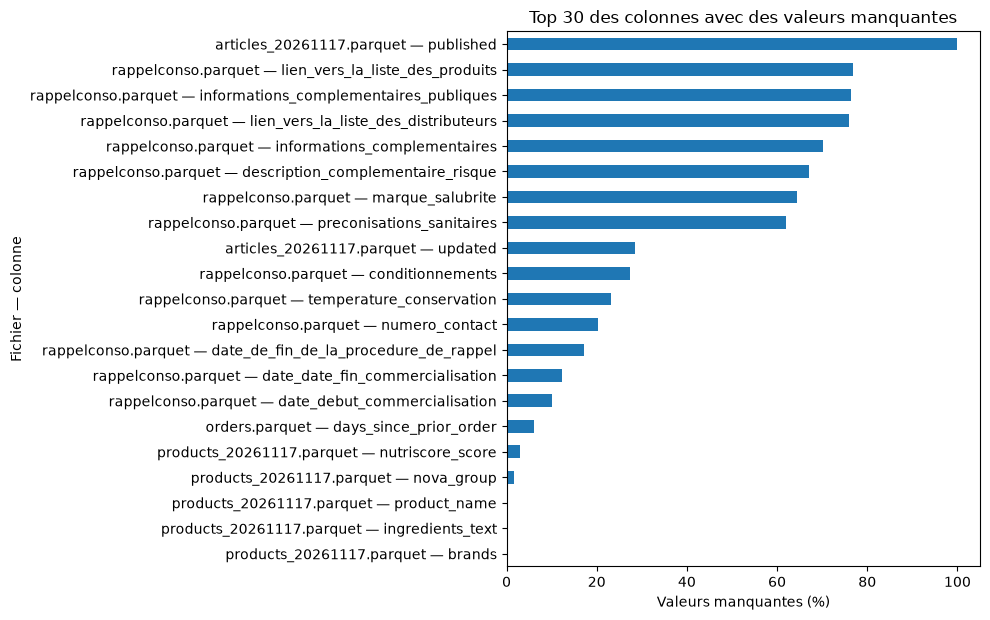

In [7]:
# Visualisation : colonnes ayant au moins une valeur manquante
missing_to_plot = (
    missing_df[missing_df["valeurs_manquantes"] > 0]
    .sort_values("taux_manquant_pct", ascending=False)
    .head(30)
)

if not missing_to_plot.empty:
    labels = missing_to_plot["fichier"] + " — " + missing_to_plot["colonne"]
    ax = missing_to_plot.set_index(labels)["taux_manquant_pct"].sort_values().plot(
        kind="barh", figsize=(10, max(5, len(missing_to_plot) * 0.3))
    )
    ax.set_xlabel("Valeurs manquantes (%)")
    ax.set_ylabel("Fichier — colonne")
    ax.set_title("Top 30 des colonnes avec des valeurs manquantes")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune valeur manquante détectée.")

## 6. Statistiques descriptives sur les échantillons

Ces statistiques portent uniquement sur les échantillons affichés ici. Elles servent à repérer les formats et valeurs à examiner ; elles ne remplacent pas les statistiques calculées sur l'ensemble des données.

In [8]:
for file_name, sample_df in samples.items():
    print("\n" + "=" * 90)
    print(file_name)
    display(sample_df.describe(include="all").T)


data\raw\instacart\aisles.parquet


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
aisle_id,8.0,NaN,NaN,NaN,4.5,2.44949,1.0,2.75,4.5,6.25,8.0
aisle,8,8,prepared soups salads,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN



data\raw\instacart\departments.parquet


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
department_id,8.0,NaN,NaN,NaN,4.5,2.44949,1.0,2.75,4.5,6.25,8.0
department,8,8,frozen,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN



data\raw\instacart\order_products__prior.parquet


,count,mean,std,min,25%,50%,75%,max
order_id,8.0,2.000,0.000000,2.0,2.00,2.0,2.00,2.0
product_id,8.0,25892.375,15130.555253,1819.0,15677.25,29510.0,34875.25,45918.0
add_to_cart_order,8.0,4.500,2.449490,1.0,2.75,4.5,6.25,8.0
reordered,8.0,0.750,0.462910,0.0,0.75,1.0,1.00,1.0


... (8 outputs left out)


data\raw\rappelconso\rappelconso.parquet


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gtin,8.0,NaN,NaN,NaN,3818175960469.375,1326169796462.742676,3258561419695.0,3258561419713.75,3312115710275.5,3449379709597.0,7079317191322.0
numero_fiche,8,4,2026-11-0107,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
numero_version,8.0,NaN,NaN,NaN,1.375,0.517549,1.0,1.0,1.0,2.0,2.0
nature_juridique_rappel,8,1,volontaire (sans arrêté préfectoral),8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie_produit,8,2,alimentation,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sous_categorie_produit,8,3,lait et produits laitiers,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marque_produit,8,4,belle france,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modeles_ou_references,8,4,fromage blanc belle france 0% 500g¤fromage blanc belle france 0% 1kg¤fromage blanc belle france 3% 500g¤fromage blan...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
identification_produits,8,4,3258561419695$voir liste des produits en pièce jointe$date limite de consommation$2026-12-01$|3258561419701$voir lis...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
conditionnements,3,2,papier,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN



data\raw\scraping\articles_20261117.parquet


,count,unique,top,freq
url,7,7,https://www.ecologie.gouv.fr/politiques-publiques/pesticides-pollutions-diffuses,1
title,7,1,Paramètres d'affichage,7
published,0,0,NaN,NaN
updated,5,4,10 septembre 2025,2
published_text,7,7,03 juin 2019,1
text,7,7,Temps de lecture : 7 minutes\nPesticides\nAlimentation et agriculture durables\nPartager la page\nLa contamination d...,1
scraped_at,7,1,2026-11-17T12:02:46+00:00,7
date_reference,7,6,10 septembre 2025,2
date_reference_type,7,2,mise_a_jour,5
licence,7,1,Licence Ouverte Etalab 2.0,7


## 7. Premiers contrôles de doublons sur les échantillons

Attention : le résultat ci-dessous concerne les échantillons uniquement. Il ne permet pas de conclure qu'un fichier complet ne contient aucun doublon.

In [9]:

# 07 - Contrôle préliminaire des doublons sur les échantillons

sample_duplicate_report = []

for file_name, sample_df in samples.items():

    # On identifie uniquement les colonnes comparables
    comparable_cols = [
        col for col in sample_df.columns
        if not sample_df[col].apply(
            lambda x: isinstance(x, (np.ndarray, list, dict, set))
        ).any()
    ]

    if comparable_cols:
        duplicate_count = int(
            sample_df.duplicated(subset=comparable_cols).sum()
        )
    else:
        duplicate_count = 0

    sample_duplicate_report.append({
        "fichier": file_name,
        "lignes_echantillon": len(sample_df),
        "colonnes_comparables": len(comparable_cols),
        "doublons_echantillon": duplicate_count
    })

duplicate_df = pd.DataFrame(sample_duplicate_report)

display(duplicate_df)


,fichier,lignes_echantillon,colonnes_comparables,doublons_echantillon
0,data\raw\instacart\aisles.parquet,8,2,0
1,data\raw\instacart\departments.parquet,8,2,0
2,data\raw\instacart\order_products__prior.parquet,8,4,0
3,data\raw\instacart\order_products__train.parquet,8,4,0
4,data\raw\instacart\orders.parquet,8,7,0
5,data\raw\instacart\products.parquet,8,4,0
6,data\raw\openfoodfacts\products_20261117.parquet,8,11,0
7,data\raw\rappelconso\rappelconso.parquet,8,37,0
8,data\raw\scraping\articles_20261117.parquet,7,13,0


## 8. Synthèse et points à investiguer

À la fin de l'audit, noter les anomalies qui devront être traitées ou arbitrées dans la couche Silver.

Exemples de points à vérifier :
- colonnes avec beaucoup de valeurs manquantes ;
- identifiants présents et unicité attendue ;
- formats des dates ;
- cohérence des unités et des prix ;
- doublons métier (à définir selon chaque source) ;
- valeurs impossibles ou incohérentes.

**Ne pas supprimer automatiquement une colonne ou une ligne uniquement parce qu'elle contient des valeurs manquantes ou semble atypique.** La décision dépend de la signification métier de la variable.

In [10]:
# Tableau récapitulatif des fichiers
audit_summary = (
    metadata_df
    .merge(
        inventory[["source", "fichier", "taille_Mo"]],
        on=["source", "fichier"],
        how="left"
    )
    .sort_values(["source", "fichier"])
    .reset_index(drop=True)
)

display(audit_summary)

print("\nAudit Bronze terminé.")
print("Aucun fichier source n'a été modifié.")

,source,fichier,lignes,colonnes,groupes,taille_Mo
0,instacart,aisles.parquet,134,2,1,0.00
1,instacart,departments.parquet,21,2,1,0.00
2,instacart,order_products__prior.parquet,32434489,4,551,125.81
3,instacart,order_products__train.parquet,1384617,4,24,5.37
4,instacart,orders.parquet,3421083,7,104,31.60
5,instacart,products.parquet,49688,4,3,1.45
6,openfoodfacts,products_20261117.parquet,1000,15,1,0.21
7,rappelconso,rappelconso.parquet,19018,37,1,4.36
8,scraping,articles_20261117.parquet,7,13,1,0.05



Audit Bronze terminé.
Aucun fichier source n'a été modifié.


In [10]:
from pathlib import Path
import sys

# Retrouver la racine du projet
ROOT = Path.cwd()

if not (ROOT / "src" / "panier_vert" / "storage" / "rustfs.py").exists():
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.panier_vert.storage.rustfs import (
    s3,
    RUSTFS_BUCKET,
    ensure_bucket,
    upload_file_to_bronze
)

print("Projet :", ROOT)
print("Bucket :", RUSTFS_BUCKET)

Projet : c:\Users\akono\projet_mspr_panier_vert
Bucket : panier-vert


In [7]:
# Fichiers bruts à transférer
files_to_upload = {
    "instacart": [
        "aisles.parquet",
        "departments.parquet",
        "orders.parquet",
        "order_products__prior.parquet",
        "order_products__train.parquet",
        "products.parquet",
    ],
    "openfoodfacts": [
        "products_20261117.parquet",
    ],
    "rappelconso": [
        "rappelconso.parquet",
    ],
    "web_source": [
        "articles_20261117.parquet",
    ],
}

ensure_bucket()

uploaded_files = []

for source, filenames in files_to_upload.items():

    for filename in filenames:

        local_path = ROOT / "data" / "raw" / (
            "scraping" if source == "web_source" else source
        ) / filename

        if not local_path.exists():
            raise FileNotFoundError(
                f"Fichier introuvable : {local_path}"
            )

        # Transfert vers Bronze
        object_key = upload_file_to_bronze(
            local_path=local_path,
            source=source,
            filename=filename
        )

        uploaded_files.append({
            "source": source,
            "filename": filename,
            "object_key": object_key,
            "local_size": local_path.stat().st_size
        })

print(f"\nNombre de fichiers transférés : {len(uploaded_files)}")

Bucket existant : panier-vert
Fichier envoyé : s3://panier-vert/bronze/instacart/aisles.parquet
Fichier envoyé : s3://panier-vert/bronze/instacart/departments.parquet
Fichier envoyé : s3://panier-vert/bronze/instacart/orders.parquet
Fichier envoyé : s3://panier-vert/bronze/instacart/order_products__prior.parquet
Fichier envoyé : s3://panier-vert/bronze/instacart/order_products__train.parquet
Fichier envoyé : s3://panier-vert/bronze/instacart/products.parquet
Fichier envoyé : s3://panier-vert/bronze/openfoodfacts/products_20261117.parquet
Fichier envoyé : s3://panier-vert/bronze/rappelconso/rappelconso.parquet
Fichier envoyé : s3://panier-vert/bronze/web_source/articles_20261117.parquet

Nombre de fichiers transférés : 9


In [8]:
import pandas as pd

verification = []

for file in uploaded_files:

    response = s3.head_object(
        Bucket=RUSTFS_BUCKET,
        Key=file["object_key"]
    )

    remote_size = response["ContentLength"]
    local_size = file["local_size"]

    verification.append({
        "source": file["source"],
        "fichier": file["filename"],
        "taille_locale": local_size,
        "taille_rustfs": remote_size,
        "statut": "OK" if local_size == remote_size else "ERREUR"
    })

df_verification = pd.DataFrame(verification)

display(df_verification)

assert (df_verification["statut"] == "OK").all(), \
    "Certains fichiers n'ont pas été transférés correctement."

print("Tous les fichiers Bronze ont été vérifiés.")

,source,fichier,taille_locale,taille_rustfs,statut
0,instacart,aisles.parquet,3406,3406,OK
1,instacart,departments.parquet,1094,1094,OK
2,instacart,orders.parquet,33134387,33134387,OK
3,instacart,order_products__prior.parquet,131921315,131921315,OK
4,instacart,order_products__train.parquet,5626099,5626099,OK
5,instacart,products.parquet,1515546,1515546,OK
6,openfoodfacts,products_20261117.parquet,219496,219496,OK
7,rappelconso,rappelconso.parquet,4575690,4575690,OK
8,web_source,articles_20261117.parquet,55618,55618,OK


Tous les fichiers Bronze ont été vérifiés.


In [9]:
list_bronze_objects()

bronze/instacart/aisles.parquet | 3.33 Ko
bronze/instacart/departments.parquet | 1.07 Ko
bronze/instacart/order_products__prior.parquet | 128829.41 Ko
bronze/instacart/order_products__train.parquet | 5494.24 Ko
bronze/instacart/orders.parquet | 32357.80 Ko
bronze/instacart/products.parquet | 1480.03 Ko
bronze/openfoodfacts/products_20261117.parquet | 214.35 Ko
bronze/rappelconso/rappelconso.parquet | 4468.45 Ko
bronze/web_source/articles_20261117.parquet | 54.31 Ko


[{'Key': 'bronze/instacart/aisles.parquet',
  'LastModified': datetime.datetime(2026, 11, 18, 11, 8, 17, 853000, tzinfo=tzutc()),
  'ETag': '"a7fd7b5b43ef9d904d0c7049da1856ab"',
  'Size': 3406,
  'StorageClass': 'STANDARD'},
 {'Key': 'bronze/instacart/departments.parquet',
  'LastModified': datetime.datetime(2026, 11, 18, 11, 8, 17, 929000, tzinfo=tzutc()),
  'ETag': '"07e751b957a24de168f855c5bbc3313c"',
  'Size': 1094,
  'StorageClass': 'STANDARD'},
 {'Key': 'bronze/instacart/order_products__prior.parquet',
  'LastModified': datetime.datetime(2026, 11, 18, 11, 8, 19, 659000, tzinfo=tzutc()),
  'ETag': '"38b057b1a292cfc24ad16fee7e3ccac2-16"',
  'Size': 131921315,
  'StorageClass': 'STANDARD'},
 {'Key': 'bronze/instacart/order_products__train.parquet',
  'LastModified': datetime.datetime(2026, 11, 18, 11, 8, 19, 803000, tzinfo=tzutc()),
  'ETag': '"7468358b9760efcdeddc905773e09f65"',
  'Size': 5626099,
  'StorageClass': 'STANDARD'},
 {'Key': 'bronze/instacart/orders.parquet',
  'LastMod